# Логистическая регрессия: вероятность, ошибка и качество классификации

Ноутбук изучает бинарную классификацию на общем учебном источнике модуля. Подготовка и обучение заключены в единый Pipeline; никакие статистики не вычисляются по тестовой части. Валидация используется для разбора метрик и вариантов модели.

Логистическая регрессия строит линейную оценку в пространстве подготовленных признаков и преобразует её в вероятность класса 1. Вероятность, решение по порогу и полезность действия — разные уровни анализа. Деревья и ансамбли рассматриваются в следующих файлах.

## 1. Базовая стратегия и интерфейс классификатора

Общий интерфейс Scikit-learn отделяет создание объекта от обучения. Для честного старта используется DummyClassifier, который не извлекает зависимость от признаков.

**Загрузка контекста без тестовых метрик**

Все импорты выполняются один раз. Разбиение повторяет договор первого ноутбука. Матрица признаков содержит только двенадцать разрешённых полей; будущие показатели и идентификаторы не поступают модели.

In [1]:
# Шаг М2.02.01 — Загрузка контекста без тестовых метрик
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, log_loss)

data = pd.read_csv(Path.cwd() / 'data' / 'delivery_risk.csv',
                   parse_dates=['order_ts', 'label_available_at'])
NUMERIC = ['distance_km', 'items_count', 'order_amount', 'warehouse_load',
           'customer_prior_orders', 'promised_days', 'order_hour']
CATEGORICAL = ['city', 'product_category', 'delivery_type', 'weather_forecast', 'is_weekend']
FEATURES = NUMERIC + CATEGORICAL
train = data.loc[data['order_ts'].lt('2026-07-25')].copy()
valid = data.loc[data['order_ts'].ge('2026-08-01') & data['order_ts'].lt('2026-09-24')].copy()
X_train, y_train = train[FEATURES], train['late_delivery']
X_valid, y_valid = valid[FEATURES], valid['late_delivery']
assert train['label_available_at'].max() < valid['order_ts'].min()
display(pd.Series({'Обучение': len(train), 'Валидация': len(valid),
                   'Признаков': len(FEATURES), 'Версия Scikit-learn': sklearn.__version__}).to_frame('Контекст'))

,Контекст
Обучение,7863
Валидация,2072
Признаков,12
Версия Scikit-learn,1.8.0


**Базовая модель без знания признаков**

Стратегия `prior` запоминает доли классов обучения. Она присваивает всем заявкам одинаковую вероятность и выбирает наиболее частый класс. Это обучаемая базовая частота, а не модель связи с расстоянием или нагрузкой.

In [2]:
# Шаг М2.02.02 — Базовая модель без знания признаков
baseline = DummyClassifier(strategy='prior', random_state=42)
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_valid)
baseline_probability = baseline.predict_proba(X_valid)[:, 1]
display(pd.DataFrame({'Класс': baseline.classes_, 'Доля train': baseline.class_prior_}))
print('Различных ответов на валидации:', np.unique(baseline_prediction))
print('Пример вероятностей:', baseline_probability[:5])

,Класс,Доля train
0,0,0.881852
1,1,0.118148


Различных ответов на валидации: [0]
Пример вероятностей: [0.11814829 0.11814829 0.11814829 0.11814829 0.11814829]


**Высокая accuracy без найденных задержек**

Accuracy — доля всех правильных меток. При редком положительном классе она способна быть высокой у модели, которая не находит положительные случаи вообще.

Одинаковая accuracy возможна у процедур с очень разными последствиями. Одна может создавать много лишних предупреждений, другая пропускать почти все задержки. Для понимания результата необходимо сохранять исходные счётчики ошибок и размеры соответствующих групп.

Базовая модель нужна даже при наличии сложных алгоритмов. Она показывает, какой результат достигается без знания индивидуальных признаков, и помогает заметить проблемы экспериментальной процедуры. Сравнение должно выполняться на одних и тех же заявках.

In [3]:
# Шаг М2.02.03 — Высокая accuracy без найденных задержек
baseline_accuracy = accuracy_score(y_valid, baseline_prediction)
found_late = int(((baseline_prediction == 1) & y_valid.eq(1)).sum())
display(pd.Series({'Accuracy': baseline_accuracy,
                   'Настоящих задержек': int(y_valid.sum()),
                   'Найденных задержек': found_late,
                   'Предсказано задержек': int(baseline_prediction.sum())}).to_frame('Базовая стратегия'))

,Базовая стратегия
Accuracy,0.884653
Настоящих задержек,239.000000
Найденных задержек,0.000000
Предсказано задержек,0.000000


Базовая стратегия закрепляет начальную частоту и показывает ограничение accuracy при редком событии.

## 2. Линейная оценка и логистическое преобразование

Логистическая регрессия вычисляет `z = b + Σ wⱼxⱼ`, затем `p = 1 / (1 + exp(-z))`. Обучаемыми параметрами являются коэффициенты и свободный член. Настройки процедуры обучения являются гиперпараметрами.

**Логистическая функция на малом примере**

Экспонента `exp(z)` — положительная функция, основанная на числе e. Сигмоида преобразует любое конечное линейное значение в число между нулём и единицей. При z=0 вероятность равна 0,5.

,Линейная оценка z,Вероятность класса 1
0,-4.0,0.0180
1,-2.0,0.1192
2,-1.0,0.2689
3,0.0,0.5000
4,1.0,0.7311
5,2.0,0.8808
6,4.0,0.9820


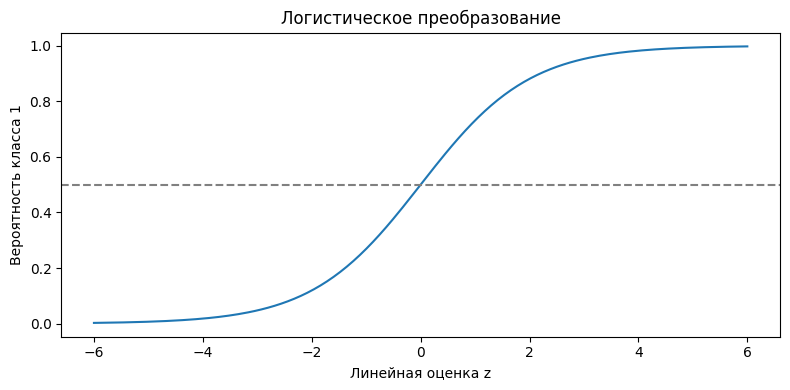

In [4]:
# Шаг М2.02.04 — Логистическая функция на малом примере
z_example = np.array([-4, -2, -1, 0, 1, 2, 4], dtype=float)
p_example = 1 / (1 + np.exp(-z_example))
display(pd.DataFrame({'Линейная оценка z': z_example, 'Вероятность класса 1': p_example}).round(4))
fig, ax = plt.subplots(figsize=(8, 4))
grid = np.linspace(-6, 6, 200)
ax.plot(grid, 1 / (1 + np.exp(-grid)))
ax.axhline(.5, color='gray', linestyle='--')
ax.set(xlabel='Линейная оценка z', ylabel='Вероятность класса 1', title='Логистическое преобразование')
fig.tight_layout()
plt.show()
plt.close(fig)

**Шансы и логарифм шансов**

Шансы определяются как `p / (1-p)` и не совпадают с вероятностью. Натуральный логарифм шансов равен линейной оценке z. Логарифм является обратной функцией экспоненты.

In [5]:
# Шаг М2.02.05 — Шансы и логарифм шансов
odds = p_example / (1 - p_example)
display(pd.DataFrame({'Вероятность': p_example, 'Шансы': odds,
                      'Логарифм шансов': np.log(odds)}).round(4))
assert np.allclose(np.log(odds), z_example)

,Вероятность,Шансы,Логарифм шансов
0,0.0180,0.0183,-4.0
1,0.1192,0.1353,-2.0
2,0.2689,0.3679,-1.0
3,0.5000,1.0000,0.0
4,0.7311,2.7183,1.0
5,0.8808,7.3891,2.0
6,0.9820,54.5982,4.0


**Штраф за неверную уверенность**

Логистическая потеря для одной метки записывается как `−y·log(p) − (1−y)·log(1−p)`. Уверенный неверный ответ получает большой штраф. Усреднение этой потери по данным называется log loss.

In [6]:
# Шаг М2.02.06 — Штраф за неверную уверенность
loss_example = pd.DataFrame({'Правильная метка': [1, 1, 1, 0, 0, 0],
                             'Оценка p': [.9, .6, .01, .1, .4, .99]})
p_loss = loss_example['Оценка p'].to_numpy()
y_loss = loss_example['Правильная метка'].to_numpy()
loss_example['Потеря'] = -y_loss * np.log(p_loss) - (1 - y_loss) * np.log(1 - p_loss)
display(loss_example.round(4))

,Правильная метка,Оценка p,Потеря
0,1,0.90,0.1054
1,1,0.60,0.5108
2,1,0.01,4.6052
3,0,0.10,0.1054
4,0,0.40,0.5108
5,0,0.99,4.6052


**Параметры модели и регуляризация**

Коэффициенты оцениваются по обучающим данным. Регуляризация ограничивает чрезмерные значения коэффициентов. В используемой настройке LogisticRegression штраф L2 зависит от суммы квадратов коэффициентов; меньший C означает более сильное ограничение.

Регуляризация ограничивает подстройку коэффициентов к особенностям конечной обучающей выборки. При чрезмерно сильном ограничении модель может не использовать полезную зависимость; при слишком слабом — сильнее реагировать на случайные особенности истории. Сам размер коэффициентов не показывает, какое из этих состояний лучше для нового окна.

Число итераций оптимизации и сложность статистической зависимости различаются. Увеличение `max_iter` даёт оптимизатору больше времени на решение той же задачи; оно не добавляет новые признаки или взаимодействия. Значение C меняет саму задачу обучения через регуляризацию.

In [7]:
# Шаг М2.02.07 — Параметры модели и регуляризация
regularization_demo = pd.DataFrame({'Набор': ['Умеренные коэффициенты', 'Большие коэффициенты'],
                                    'Коэффициенты': [[.5, -.3, .2], [5., -3., 2.]]})
regularization_demo['Сумма квадратов'] = regularization_demo['Коэффициенты'].map(lambda w: np.square(w).sum())
display(regularization_demo)
print('C — настройка обучения; coef_ — результат обучения.')

,Набор,Коэффициенты,Сумма квадратов
0,Умеренные коэффициенты,"[0.5, -0.3, 0.2]",0.38
1,Большие коэффициенты,"[5.0, -3.0, 2.0]",38.00


C — настройка обучения; coef_ — результат обучения.


Вероятность получена из линейной оценки, а обучение определяется потерей и регуляризацией. Коэффициент не является непосредственным изменением вероятности в процентных пунктах.

## 3. Обучение Pipeline и чтение результата

Подготовка и классификатор обучаются одним вызовом fit. Предсказание принимает исходную таблицу, поэтому при применении не нужно отдельно повторять заполнение и кодирование.

**Подготовка и модель в одном объекте**

Два шага Pipeline называются `prepare` и `model`. Стандартный solver `lbfgs` выполняет численную оптимизацию. Ограничение числа итераций не является числом просмотров каждого отдельного объекта.

In [8]:
# Шаг М2.02.08 — Подготовка и модель в одном объекте
prepare = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                          ('scale', StandardScaler())]), NUMERIC),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                              ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL)
])
model = Pipeline([('prepare', prepare),
                  ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=42))])
model.fit(X_train, y_train)
print('Итераций оптимизатора:', model.named_steps['model'].n_iter_)
print('Классы:', model.named_steps['model'].classes_)

Итераций оптимизатора: [18]
Классы: [0 1]


**Вероятности и порядок классов**

Столбцы predict_proba соответствуют порядку `classes_`. Для данной разметки это [0,1], поэтому вероятность задержки берётся из второго столбца. Решение predict не является самой вероятностью.

In [9]:
# Шаг М2.02.09 — Вероятности и порядок классов
class_order = model.named_steps['model'].classes_
positive_column = int(np.flatnonzero(class_order == 1)[0])
probability_matrix = model.predict_proba(X_valid)
p_valid = probability_matrix[:, positive_column]
prediction = model.predict(X_valid)
display(pd.DataFrame({'Метка': y_valid.iloc[:8].to_numpy(),
                      'p(0)': probability_matrix[:8, 0], 'p(1)': p_valid[:8],
                      'Ответ predict': prediction[:8]}).round(4))
assert np.allclose(probability_matrix.sum(axis=1), 1)
assert np.isfinite(p_valid).all() and ((p_valid >= 0) & (p_valid <= 1)).all()

,Метка,p(0),p(1),Ответ predict
0,0,0.8993,0.1007,0
1,0,0.8879,0.1121,0
2,0,0.9385,0.0615,0
3,0,0.8986,0.1014,0
4,1,0.7177,0.2823,0
5,0,0.6067,0.3933,0
6,0,0.6859,0.3141,0
7,0,0.7464,0.2536,0


**Коэффициенты и происхождение столбцов**

Коэффициенты относятся к подготовленным признакам, включая индикаторы пропусков и one-hot. Для числовой ветви единица коэффициента связана со стандартным отклонением обучения. Коэффициенты не доказывают причинного воздействия.

Сопоставление коэффициентов требует учёта подготовки. Для стандартизованного числа сдвиг на единицу связан с разбросом train, а для категории — с включением её индикатора. При нескольких связанных признаках отдельные коэффициенты могут перераспределять вклад между собой без существенного изменения общего прогноза.

Устойчивость знака и величины коэффициента по одному обучению не установлена. Она зависит от состава истории, регуляризации и взаимосвязей входных полей. Таблица коэффициентов помогает объяснить функцию модели, но не заменяет эксперимент для оценки причинного воздействия.

In [10]:
# Шаг М2.02.10 — Коэффициенты и происхождение столбцов
feature_names = model.named_steps['prepare'].get_feature_names_out()
coefficients = pd.Series(model.named_steps['model'].coef_[0], index=feature_names, name='Коэффициент')
display(pd.concat([coefficients.nsmallest(8), coefficients.nlargest(8)]).to_frame().round(4))
print('Свободный член:', model.named_steps['model'].intercept_[0])

,Коэффициент
categorical__weather_forecast_Ясно,-0.8747
categorical__is_weekend_Нет,-0.6121
categorical__delivery_type_Обычная,-0.4332
categorical__product_category_Спорт,-0.4063
categorical__city_Новосибирск,-0.3070
categorical__city_Казань,-0.2909
categorical__delivery_type_Пункт выдачи,-0.2422
categorical__product_category_Одежда,-0.2358
numeric__warehouse_load,0.6831
numeric__distance_km,0.4376


Свободный член: -0.8509143675777964


**Ручная проверка линейной оценки**

Результат decision_function должен совпадать с матричным произведением подготовленных признаков и коэффициентов плюс свободный член. Знак `@` обозначает матричное произведение.

In [11]:
# Шаг М2.02.11 — Ручная проверка линейной оценки
Z_sample = model.named_steps['prepare'].transform(X_valid.head(5))
classifier = model.named_steps['model']
manual_z = Z_sample @ classifier.coef_[0] + classifier.intercept_[0]
manual_p = 1 / (1 + np.exp(-manual_z))
display(pd.DataFrame({'z вручную': manual_z,
                      'decision_function': model.decision_function(X_valid.head(5)),
                      'p вручную': manual_p, 'p Pipeline': p_valid[:5]}).round(6))
assert np.allclose(manual_p, p_valid[:5])

,z вручную,decision_function,p вручную,p Pipeline
0,-2.189213,-2.189213,0.100723,0.100723
1,-2.069589,-2.069589,0.112088,0.112088
2,-2.725772,-2.725772,0.061470,0.061470
3,-2.181227,-2.181227,0.101449,0.101449
4,-0.933103,-0.933103,0.282296,0.282296


**Изменение расстояния при прочих равных**

Парное сравнение изменяет только один разрешённый вход. Сравниваются оценки модели, а не доказанный результат реального вмешательства. Для отсутствующих и присутствующих измерений сохраняются разные состояния индикатора пропуска.

In [12]:
# Шаг М2.02.12 — Изменение расстояния при прочих равных
reference = X_valid.loc[X_valid['distance_km'].notna()].head(1).copy()
farther = reference.copy()
farther['distance_km'] += 100
pair = pd.concat([reference, farther], ignore_index=True)
pair_p = model.predict_proba(pair)[:, positive_column]
pair_z = model.decision_function(pair)
display(pd.DataFrame({'Расстояние, км': pair['distance_km'], 'Оценка p': pair_p, 'Оценка z': pair_z}).round(4))
print('Отношение шансов:', round(float(np.exp(pair_z[1] - pair_z[0])), 4))

,"Расстояние, км",Оценка p,Оценка z
0,18.1,0.1007,-2.1892
1,118.1,0.1186,-2.0060


Отношение шансов: 1.2011


Обученный Pipeline связывает исходные столбцы с вероятностью класса 1. Формула проверена вручную, а коэффициенты прочитаны в масштабе подготовленных признаков.

## 4. Виды ошибок и качество ранжирования

Порог превращает вероятность в действие классификации. Метрики по классам зависят от порога; ROC-AUC и Average Precision оценивают порядок оценок без выбора единственного рабочего порога.

**Матрица ошибок при заданном пороге**

Строки confusion matrix соответствуют правильным классам, столбцы предсказанным. Для порядка [0,1] ячейки имеют смысл TN, FP, FN, TP. Порог 0,5 рассматривается как исходный пример, а не оптимальное решение задачи.

,Прогноз 0,Прогноз 1
Факт 0,1815,18
Факт 1,220,19


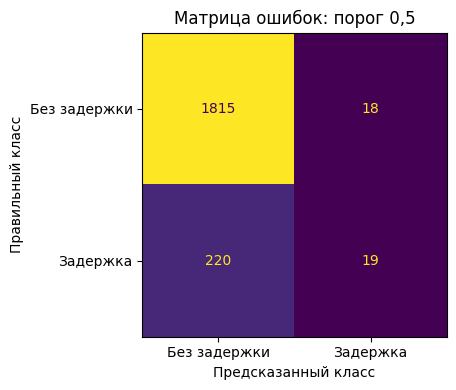

In [13]:
# Шаг М2.02.13 — Матрица ошибок при заданном пороге
threshold = .5
pred_at_half = (p_valid >= threshold).astype(int)
cm = confusion_matrix(y_valid, pred_at_half, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
display(pd.DataFrame(cm, index=['Факт 0', 'Факт 1'], columns=['Прогноз 0', 'Прогноз 1']))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Без задержки', 'Задержка']).plot(ax=ax, colorbar=False)
ax.set(xlabel='Предсказанный класс', ylabel='Правильный класс', title='Матрица ошибок: порог 0,5')
fig.tight_layout()
plt.show()
plt.close(fig)

**Precision Recall и F1 через счётчики**

Precision отвечает, какая доля предупреждений оказалась верной. Recall — какая доля настоящих событий обнаружена. F1 объединяет precision и recall гармоническим средним, но не учитывает истинно отрицательные ответы и не является универсальной мерой пользы.

In [14]:
# Шаг М2.02.14 — Precision Recall и F1 через счётчики
manual_precision = tp / (tp + fp) if tp + fp else 0
manual_recall = tp / (tp + fn) if tp + fn else 0
manual_f1 = 2 * manual_precision * manual_recall / (manual_precision + manual_recall) if manual_precision + manual_recall else 0
metric_table = pd.DataFrame({'Вручную': [(tp + tn) / cm.sum(), manual_precision, manual_recall, manual_f1],
                             'Scikit-learn': [accuracy_score(y_valid, pred_at_half),
                              precision_score(y_valid, pred_at_half, zero_division=0),
                              recall_score(y_valid, pred_at_half, zero_division=0),
                              f1_score(y_valid, pred_at_half, zero_division=0)]},
                            index=['Accuracy', 'Precision', 'Recall', 'F1'])
display(metric_table.round(4))
assert np.allclose(metric_table['Вручную'], metric_table['Scikit-learn'])

,Вручную,Scikit-learn
Accuracy,0.8851,0.8851
Precision,0.5135,0.5135
Recall,0.0795,0.0795
F1,0.1377,0.1377


**Отчёт по обоим классам**

В classification_report support означает число настоящих примеров соответствующего класса. Macro усредняет показатели классов с одинаковым весом, weighted учитывает их размеры. Итоговое число без названия способа усреднения неоднозначно.

У precision и recall положительный класс один и тот же, но основание подсчёта различается. При интерпретации precision отправной точкой служит очередь предсказанных событий. При интерпретации recall отправной точкой служат все известные настоящие события. Эти две популяции совпадают только у идеального классификатора.

Macro и weighted усреднения полезны для общего отчёта, но способны скрыть поведение конкретного редкого класса. Для принятия решения сохраняются показатели этого класса и число заявок, которым назначено предупреждение.

In [15]:
# Шаг М2.02.15 — Отчёт по обоим классам
report = classification_report(y_valid, pred_at_half,
                                target_names=['Без задержки', 'Задержка'],
                                output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))

,precision,recall,f1-score,support
Без задержки,0.8919,0.9902,0.9385,1833.0000
Задержка,0.5135,0.0795,0.1377,239.0000
accuracy,0.8851,0.8851,0.8851,0.8851
macro avg,0.7027,0.5348,0.5381,2072.0000
weighted avg,0.8482,0.8851,0.8461,2072.0000


**Изменение порога без нового обучения**

Для каждого порога используются те же вероятности. Снижение границы обычно увеличивает число предупреждений и полноту, одновременно меняя precision. Обучение модели и выбор правила решения выполняют разные роли.

In [16]:
# Шаг М2.02.16 — Изменение порога без нового обучения
threshold_rows = []
for t in [.1, .2, .35, .5, .7]:
    labels = (p_valid >= t).astype(int)
    threshold_rows.append({'Порог': t, 'Предупреждений': int(labels.sum()),
                           'Precision': precision_score(y_valid, labels, zero_division=0),
                           'Recall': recall_score(y_valid, labels, zero_division=0),
                           'F1': f1_score(y_valid, labels, zero_division=0)})
display(pd.DataFrame(threshold_rows).round(4))

,Порог,Предупреждений,Precision,Recall,F1
0,0.10,859,0.1909,0.6862,0.2987
1,0.20,370,0.2892,0.4477,0.3514
2,0.35,118,0.4661,0.2301,0.3081
3,0.50,37,0.5135,0.0795,0.1377
4,0.70,4,0.5000,0.0084,0.0165


**ROC-кривая и вероятность правильного порядка**

ROC-кривая показывает Recall по оси Y и долю FP среди всех настоящих отрицательных по оси X. ROC-AUC оценивает ранжирование; в бинарной задаче это вероятность поставить случайный положительный пример выше случайного отрицательного с половинным вкладом равных оценок.

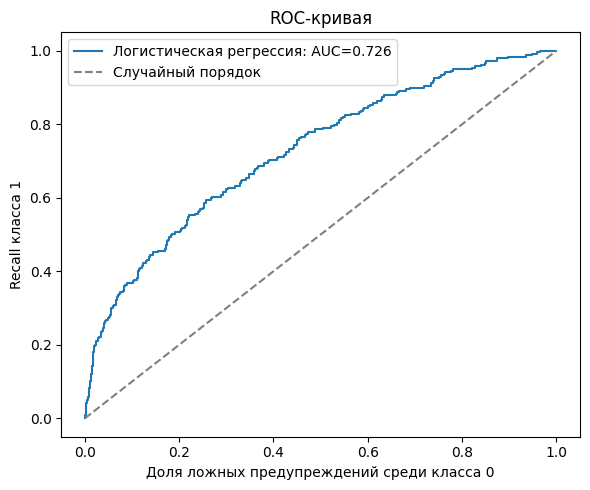

In [17]:
# Шаг М2.02.17 — ROC-кривая и вероятность правильного порядка
fpr, tpr, roc_thresholds = roc_curve(y_valid, p_valid)
roc_auc = roc_auc_score(y_valid, p_valid)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f'Логистическая регрессия: AUC={roc_auc:.3f}')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Случайный порядок')
ax.set(xlabel='Доля ложных предупреждений среди класса 0', ylabel='Recall класса 1', title='ROC-кривая')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

**Precision Recall кривая и Average Precision**

PR-кривая описывает соотношение precision и recall. Average Precision (AP) суммирует precision с весами, равными приращениям recall при изменении порога; это не автоматически площадь трапеций под нарисованной линией. Базовый ориентир зависит от частоты положительного класса.

Ранжирующая метрика не выбирает рабочую точку. Модели с похожей AP могут различаться в той верхней части очереди, которую реально можно обработать. Поэтому после сравнения общего порядка понадобится проверка конкретного ограничения на количество заявок.

AP зависит от базовой частоты положительного класса. Сравнивать её значения на разных популяциях без указания частоты и состава наблюдений рискованно. В этом модуле все кандидаты оцениваются на одном окне; это исключает простую подмену качества разницей проверочных наборов.

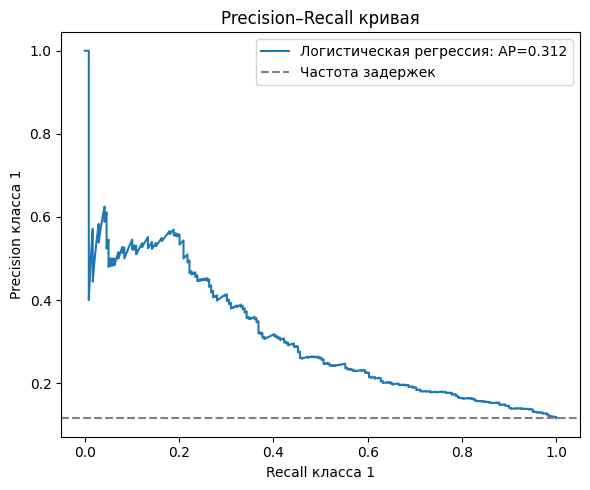

AP baseline / model: 0.11534749034749035 0.31249428455411904


In [18]:
# Шаг М2.02.18 — Precision Recall кривая и Average Precision
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_valid, p_valid)
ap = average_precision_score(y_valid, p_valid)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(pr_recall, pr_precision, label=f'Логистическая регрессия: AP={ap:.3f}')
ax.axhline(y_valid.mean(), color='gray', linestyle='--', label='Частота задержек')
ax.set(xlabel='Recall класса 1', ylabel='Precision класса 1', title='Precision–Recall кривая')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)
print('AP baseline / model:', average_precision_score(y_valid, baseline_probability), ap)

**Качество вероятностей через log loss**

Метрика log loss использует уже разобранную логистическую потерю и оценивает вероятности, а не только порядок. Меньшее значение лучше. ROC-AUC и AP могут сохраняться при изменении уверенности, которое заметно меняет log loss.

In [19]:
# Шаг М2.02.19 — Качество вероятностей через log loss
display(pd.DataFrame({'Модель': ['Базовая частота', 'Логистическая регрессия'],
                      'ROC-AUC': [roc_auc_score(y_valid, baseline_probability), roc_auc],
                      'AP': [average_precision_score(y_valid, baseline_probability), ap],
                      'Log loss': [log_loss(y_valid, baseline_probability), log_loss(y_valid, p_valid)]}).round(4))

,Модель,ROC-AUC,AP,Log loss
0,Базовая частота,0.5000,0.1153,0.3576
1,Логистическая регрессия,0.7257,0.3125,0.3201


Получены показатели с явными знаменателями и сравнением с базовой стратегией. Ранжирование, оценка вероятностей и бинарное решение рассматриваются раздельно.

## 5. Сложность модели веса классов и объём истории

Проверка вариантов на validation является частью выбора. Итоговое качество после такого выбора должно оцениваться на ещё не использованном test. Здесь сравнения служат изучению механизма.

**Изменение C и норма коэффициентов**

`clone` создаёт новый необученный объект с теми же настройками. Состояние прежнего fit в него не переносится. `set_params` обращается к вложенному шагу через двойное подчёркивание.

In [20]:
# Шаг М2.02.20 — Изменение C и норма коэффициентов
c_results = []
for c_value in [.05, 1., 20.]:
    candidate = clone(model).set_params(model__C=c_value)
    candidate.fit(X_train, y_train)
    c_results.append({'C': c_value,
                       'AP train': average_precision_score(y_train, candidate.predict_proba(X_train)[:, 1]),
                       'AP valid': average_precision_score(y_valid, candidate.predict_proba(X_valid)[:, 1]),
                       'Норма коэффициентов': np.linalg.norm(candidate.named_steps['model'].coef_)})
display(pd.DataFrame(c_results).round(4))

,C,AP train,AP valid,Норма коэффициентов
0,0.05,0.3450,0.3103,1.2705
1,1.00,0.3452,0.3125,1.7087
2,20.00,0.3453,0.3123,1.7346


**Веса классов меняют задачу обучения**

`class_weight='balanced'` увеличивает относительный вклад примеров редкого класса в функцию обучения. Это не добавляет новые наблюдения и не выбирает порог автоматически. После изменения весов вероятности требуют самостоятельной проверки.

In [21]:
# Шаг М2.02.21 — Веса классов меняют задачу обучения
balanced_model = clone(model).set_params(model__class_weight='balanced')
balanced_model.fit(X_train, y_train)
p_balanced = balanced_model.predict_proba(X_valid)[:, 1]
weight_results = []
for name, probs in [('Обычные веса', p_valid), ('Balanced', p_balanced)]:
    labels = (probs >= .5).astype(int)
    weight_results.append({'Вариант': name, 'Средняя оценка риска': probs.mean(),
                           'AP': average_precision_score(y_valid, probs),
                           'Precision при 0,5': precision_score(y_valid, labels, zero_division=0),
                           'Recall при 0,5': recall_score(y_valid, labels, zero_division=0)})
display(pd.DataFrame(weight_results).round(4))

,Вариант,Средняя оценка риска,AP,"Precision при 0,5","Recall при 0,5"
0,Обычные веса,0.1232,0.3125,0.5135,0.0795
1,Balanced,0.4296,0.3072,0.2097,0.6527


**Срез поверхности риска**

Визуализация меняет расстояние и нагрузку, удерживая остальные признаки в одном контексте. Это срез обученной функции, а не распределение всех настоящих заказов.

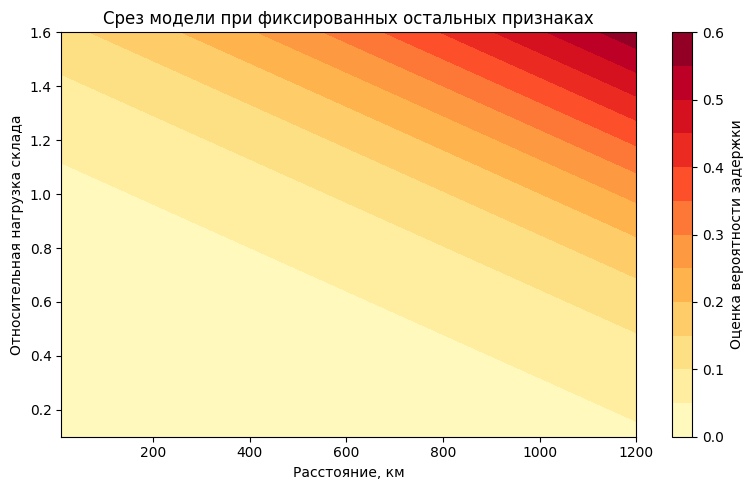

In [22]:
# Шаг М2.02.22 — Срез поверхности риска
distance_grid, load_grid = np.meshgrid(np.linspace(10, 1_200, 60), np.linspace(.1, 1.6, 60))
context = X_train.mode().iloc[0]
surface_input = pd.DataFrame([context.to_dict()] * distance_grid.size)[FEATURES]
surface_input['distance_km'] = distance_grid.ravel()
surface_input['warehouse_load'] = load_grid.ravel()
surface_risk = model.predict_proba(surface_input)[:, 1].reshape(distance_grid.shape)
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.contourf(distance_grid, load_grid, surface_risk, levels=12, cmap='YlOrRd')
fig.colorbar(image, ax=ax, label='Оценка вероятности задержки')
ax.set(xlabel='Расстояние, км', ylabel='Относительная нагрузка склада', title='Срез модели при фиксированных остальных признаках')
fig.tight_layout()
plt.show()
plt.close(fig)

**Размер обучающей истории**

Увеличивается только начальный фрагмент train, а validation остаётся прежней. Последовательный отбор сохраняет направление времени. Рост объёма не гарантирует монотонного улучшения на конечной проверке.

In [23]:
# Шаг М2.02.23 — Размер обучающей истории
history_results = []
for fraction in [.2, .4, .7, 1.]:
    size = int(len(X_train) * fraction)
    history_model = clone(model)
    history_model.fit(X_train.iloc[:size], y_train.iloc[:size])
    history_results.append({'Обучающих строк': size,
                            'AP на своём train': average_precision_score(y_train.iloc[:size], history_model.predict_proba(X_train.iloc[:size])[:, 1]),
                            'AP на общей validation': average_precision_score(y_valid, history_model.predict_proba(X_valid)[:, 1])})
display(pd.DataFrame(history_results).round(4))

,Обучающих строк,AP на своём train,AP на общей validation
0,1572,0.3881,0.2905
1,3145,0.3531,0.2992
2,5504,0.3366,0.3046
3,7863,0.3452,0.3125


Изучены изменения коэффициентов, весов и объёма истории. Все сравнения относятся к одному валидационному окну, а тест остаётся отложенным.

## 6. Проверочные задачи и границы вывода

Контрольные задачи содержат решения и результаты. Они проверяют правильность понимания ответа модели и ограничений эксперимента, не вводя отдельный режим самостоятельной работы.

**Очередь заявок по риску**

Ранжирование не требует немедленного перевода всех заявок в классы. Для разбора показаны первые строки валидационной очереди и доступные при оформлении признаки.

In [24]:
# Шаг М2.02.24 — Очередь заявок по риску
risk_queue = valid[['request_id', 'order_ts', 'distance_km', 'warehouse_load', 'delivery_type']].copy()
risk_queue['risk_score'] = p_valid
display(risk_queue.sort_values(['risk_score', 'request_id'], ascending=[False, True]).head(8))
assert risk_queue['request_id'].is_unique
print('Порог не выбирался по тестовой части.')

,request_id,order_ts,distance_km,warehouse_load,delivery_type,risk_score
8808,8809,2026-08-18 15:40:28,1224.3,0.882,Экспресс,0.736279
9973,9974,2026-09-18 00:40:56,705.2,1.357,Экспресс,0.729303
9851,9852,2026-09-14 20:20:24,1295.7,1.261,Обычная,0.723065
9129,9130,2026-08-27 00:32:34,1151.4,1.326,Обычная,0.702068
9514,9515,2026-09-06 01:27:34,881.3,0.943,Экспресс,0.671287
8219,8220,2026-08-03 07:06:11,929.0,1.365,Обычная,0.663345
9842,9843,2026-09-14 14:42:29,1500.0,0.804,Обычная,0.661352
8743,8744,2026-08-16 23:00:01,857.3,1.165,Экспресс,0.656062


Порог не выбирался по тестовой части.


**Отрицательный контроль с перемешанной целью**

Перемешивание меток train разрушает связь признаков с исходом и оставляет примерно ту же базовую частоту. Проверяется отдельный учебный вариант; исходный набор не изменяется.

Отрицательный контроль не используется для выбора рабочей модели: обученный на перемешанной цели объект является отдельной диагностической процедурой. Исходные правильные ответы и основной Pipeline сохраняются. Повторяемость обеспечивается фиксированным генератором перестановки.

Результат контроля нужно читать с учётом случайных колебаний. AP может немного отличаться от частоты задержек даже без полезной зависимости. Заметное устойчивое превышение потребовало бы отдельного исследования, а не автоматического признания нового сигнала.

In [25]:
# Шаг М2.02.25 — Отрицательный контроль с перемешанной целью
rng = np.random.default_rng(42)
shuffled_target = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)
negative_control = clone(model)
negative_control.fit(X_train, shuffled_target)
control_p = negative_control.predict_proba(X_valid)[:, 1]
display(pd.Series({'AP правильной разметки': ap,
                   'AP перемешанной разметки': average_precision_score(y_valid, control_p),
                   'Частота задержек validation': y_valid.mean()}).to_frame('Контроль'))

,Контроль
AP правильной разметки,0.312494
AP перемешанной разметки,0.093191
Частота задержек validation,0.115347


**Паспорт обученного решения**

Итог закрепляет назначение вероятности и происхождение метрик. Проверки целостности не заменяют окончательную оценку на ещё не использованном тесте.

In [26]:
# Шаг М2.02.26 — Паспорт обученного решения
checks = pd.Series({
    'Вероятности имеют размер валидации': len(p_valid) == len(valid),
    'Класс 1 определён явно': class_order[positive_column] == 1,
    'Все оценки конечны': np.isfinite(p_valid).all(),
    'Будущие поля исключены': not bool(set(FEATURES) & {'actual_delay_hours', 'compensation_paid'}),
    'Исходные X и y согласованы': X_train.index.equals(y_train.index)
}, name='Проверено')
display(checks.to_frame())
assert checks.all()
display(pd.Series({'Validation AP': ap, 'Validation ROC-AUC': roc_auc,
                   'Validation log loss': log_loss(y_valid, p_valid)}, name='Логистическая регрессия').to_frame().round(4))

,Проверено
Вероятности имеют размер валидации,True
Класс 1 определён явно,True
Все оценки конечны,True
Будущие поля исключены,True
Исходные X и y согласованы,True


,Логистическая регрессия
Validation AP,0.3125
Validation ROC-AUC,0.7257
Validation log loss,0.3201


Получены осмысленные вероятности и проверочные сравнения. Улучшение относительно базовой частоты рассмотрено с учётом постановки, а не только по одному числу.

## Полученный результат

Обучены базовая стратегия и логистическая регрессия с единой подготовкой. Проверены формула, вероятности, коэффициенты, матрица ошибок и несколько критериев качества. Изучены пороги, регуляризация, веса классов и объём истории.

Тестовые метрики не вычислялись. Далее дерево и лес будут решать ту же задачу на тех же календарных частях, чтобы сравнение касалось алгоритма и процедуры выбора.

## Документация

[Логистическая регрессия](https://scikit-learn.org/1.8/modules/linear_model.html#logistic-regression)

[Метрики классификации](https://scikit-learn.org/1.8/modules/model_evaluation.html)

[Average Precision](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.average_precision_score.html)